In [40]:
# ==============================================================================
# PASO 1 Y PASO 2: Corrección de Transposición y Alineación con Fenotipos
# ==============================================================================

setwd("/home/pazzz/Escritorio/TALLER OMICS/U2")

library(readxl)
library(tidyverse)

cat("1. Cargando genotipos desde pone.0191305.s002.xlsx...\n")
geno_raw <- read_excel("pone.0191305.s002.xlsx", sheet = 1)

# Extraer IDs de SNPs (filas) e IDs de Muestras/Líneas (columnas)
snp_ids  <- geno_raw[[1]]                     # Nombres de SNPs (IWA...)
taxa_ids <- colnames(geno_raw)[-1]            # Nombres de líneas (HOLLIS, HT080002...)

cat("Muestras detectadas:", length(taxa_ids), "| SNPs detectados:", length(snp_ids), "\n")

# Transponer para obtener la orientación Muestras (filas) x SNPs (columnas)
geno_data <- as.data.frame(t(geno_raw[, -1]))
colnames(geno_data) <- snp_ids
rownames(geno_data) <- taxa_ids

# Función para convertir alelos (AA, BB, AB, NC) a numérico (0, 1, 2)
recode_snp <- function(col) {
  col <- trimws(as.character(col))
  col[col %in% c("NC", "N/A", "NA", "-", "NN", "", "0")] <- NA
  
  unique_vals <- na.omit(unique(col))
  is_het <- col %in% c("AB", "BA", "H", "HE")
  
  homo_vals <- setdiff(unique_vals, c("AB", "BA", "H", "HE"))
  if (length(homo_vals) == 0) return(rep(NA, length(col)))
  
  counts <- table(col[!is_het & !is.na(col)])
  if (length(counts) == 0) return(rep(NA, length(col)))
  
  ref_allele <- names(sort(counts, decreasing = TRUE))[1]
  alt_allele <- if(length(counts) > 1) names(sort(counts, decreasing = TRUE))[2] else NULL
  
  num_vec <- rep(NA, length(col))
  num_vec[col == ref_allele] <- 0
  num_vec[is_het] <- 1
  if (!is.null(alt_allele)) {
    num_vec[col == alt_allele] <- 2
  }
  return(num_vec)
}

cat("2. Recodificando a formato aditivo numérico (0, 1, 2)...\n")
geno_num_list <- lapply(geno_data, recode_snp)
geno_matrix <- do.call(cbind, geno_num_list)
rownames(geno_matrix) <- taxa_ids

# Filtrar muestras por datos faltantes (>10% NA)
sample_missing <- rowMeans(is.na(geno_matrix))
keep_samples   <- sample_missing <= 0.10
geno_clean     <- geno_matrix[keep_samples, ]

cat("Muestras retenidas:", sum(keep_samples), "de", length(taxa_ids), "\n") # Debe dar ~395

# Filtrar SNPs por MAF (>=10%) y Missing (<=10%)
calc_maf <- function(snp_vec) {
  valid <- snp_vec[!is.na(snp_vec)]
  if (length(valid) == 0) return(0)
  p <- mean(valid) / 2
  return(min(p, 1 - p))
}

snp_missing <- colMeans(is.na(geno_clean))
maf_values  <- apply(geno_clean, 2, calc_maf)

keep_snps <- (snp_missing <= 0.10) & (maf_values >= 0.10)
geno_filtered <- geno_clean[, keep_snps]

cat("SNPs retenidos finales:", sum(keep_snps), "\n") # Debe dar ~6,086

# Guardar la matriz limpia (GD) para GAPIT
GD_output <- data.frame(Taxa = rownames(geno_filtered), geno_filtered, check.names = FALSE)
write.table(GD_output, file = "genotype_filtered_numeric.txt", 
            sep = "\t", quote = FALSE, row.names = FALSE)


# ==============================================================================
# PASO 2: ALINEACIÓN CON FENOTIPOS
# ==============================================================================

cat("\n--- Procesando Paso 2: Alineación de Fenotipos ---\n")

pheno_raw <- read_excel("pone.0191305.s003.xlsx", sheet = 1)
colnames(pheno_raw)[1] <- "Taxa"
pheno_raw$Taxa <- trimws(as.character(pheno_raw$Taxa))

genotyped_taxa <- trimws(as.character(GD_output$Taxa))

# Filtrar y alinear
pheno_aligned <- pheno_raw %>%
  filter(Taxa %in% genotyped_taxa)

cat("Muestras alineadas exitosamente entre genotipo y fenotipo:", nrow(pheno_aligned), "\n")

if (nrow(pheno_aligned) > 0) {
  write.table(pheno_aligned, file = "GAPIT_Phenotypes_StripeRust.txt", 
              sep = "\t", quote = FALSE, row.names = FALSE)
  cat("¡Paso 1 y Paso 2 corregidos y completados exitosamente!\n")
}

1. Cargando genotipos desde pone.0191305.s002.xlsx...
Muestras detectadas: 397 | SNPs detectados: 6086 
2. Recodificando a formato aditivo numérico (0, 1, 2)...
Muestras retenidas: 395 de 397 
SNPs retenidos finales: 5460 

--- Procesando Paso 2: Alineación de Fenotipos ---


New names:
• `` -> `...3`
• `` -> `...4`
• `` -> `...5`
• `` -> `...6`
• `` -> `...7`
• `` -> `...8`
• `` -> `...9`
• `` -> `...10`
• `` -> `...11`
• `` -> `...12`
• `` -> `...13`
• `` -> `...14`
• `` -> `...15`
• `` -> `...16`
• `` -> `...17`
• `` -> `...18`
• `` -> `...19`
• `` -> `...20`
• `` -> `...21`
• `` -> `...22`
• `` -> `...23`
• `` -> `...24`
• `` -> `...26`
• `` -> `...27`
• `` -> `...28`
• `` -> `...29`
• `` -> `...30`
• `` -> `...32`
• `` -> `...33`
• `` -> `...34`


Muestras alineadas exitosamente entre genotipo y fenotipo: 395 
¡Paso 1 y Paso 2 corregidos y completados exitosamente!


In [ ]:

# ==============================================================================
# PASO 3: GWAS statgenGWAS
# Análisis de Stripe Rust, Hessian Fly y Septoria tritici blotch
# ==============================================================================

# ------------------------------------------------------------------------------
# 0. CONFIGURACIÓN
# ------------------------------------------------------------------------------

setwd("/home/pazzz/Escritorio/TALLER OMICS/U2")

library(tidyverse)
library(statgenGWAS)

cat("\n============================================\n")
cat("INICIANDO ANALISIS GWAS CON statgenGWAS\n")
cat("============================================\n")

# ------------------------------------------------------------------------------
# 1. CARGAR ARCHIVOS
# ------------------------------------------------------------------------------

cat("\n1. Cargando archivos preparados...\n")

myY <- read.table(
  "GAPIT_Phenotypes_StripeRust.txt",
  header = TRUE,
  sep = "\t",
  check.names = FALSE,
  stringsAsFactors = FALSE
)

myGD <- read.table(
  "genotype_filtered_numeric.txt",
  header = TRUE,
  sep = "\t",
  check.names = FALSE,
  stringsAsFactors = FALSE
)

myGM <- read.table(
  "GAPIT_SNP_Map.txt",
  header = TRUE,
  sep = "\t",
  check.names = FALSE,
  stringsAsFactors = FALSE
)

# Comprobar columnas necesarias
if (!"Taxa" %in% names(myY) ||
    !"Taxa" %in% names(myGD)) {
  stop("No se encontró la columna Taxa en los archivos.")
}

if (!all(c("Name", "Chromosome", "Position") %in% names(myGM))) {
  stop("El mapa no contiene Name, Chromosome y Position.")
}

cat("Fenotipos:", dim(myY), "\n")
cat("Genotipos:", dim(myGD), "\n")
cat("Mapa SNP:", dim(myGM), "\n")


# ------------------------------------------------------------------------------
# 2. FUNCIÓN PARA CONVERTIR VALORES A NUMÉRICOS
# ------------------------------------------------------------------------------

convertir_numerico <- function(x, nombre) {

  x <- trimws(as.character(x))

  # Interpretar puntos y espacios como datos faltantes
  x[x %in% c("", ".", "NA", "NaN")] <- NA_character_

  resultado <- suppressWarnings(as.numeric(x))

  # Identificar valores que no pudieron convertirse
  invalidos <- unique(
    x[!is.na(x) & is.na(resultado)]
  )

  if (length(invalidos) > 0) {

    cat("\nValores no numéricos en:", nombre, "\n")
    print(head(invalidos, 20))

    stop(
      paste("Revisar los valores de la columna:", nombre)
    )
  }

  return(resultado)
}


# ------------------------------------------------------------------------------
# 3. PREPARAR BLOQUE PRINCIPAL DE FENOTIPOS
# ------------------------------------------------------------------------------

cat("\n2. Preparando fenotipos principales...\n")

taxa_ref <- trimws(as.character(myY$Taxa))

if (anyNA(taxa_ref) || any(taxa_ref == "")) {
  stop("Existen identificadores Taxa vacíos.")
}

if (anyDuplicated(taxa_ref)) {
  stop("Existen identificadores Taxa duplicados.")
}

# Detectar automáticamente columnas que duplican Taxa
columnas_id <- names(myY)[
  vapply(names(myY), function(nm) {

    if (nm == "Taxa") {
      return(FALSE)
    }

    identical(
      trimws(as.character(myY[[nm]])),
      taxa_ref
    )

  }, logical(1))
]

cat("Columnas duplicadas de Taxa:\n")
print(columnas_id)

# Identificador del bloque Septoria
septoria_id_col <- "...30"

# Variables fenotípicas asociadas al bloque Septoria
septoria_traits <- c(
  "Septoria tritici blotch",
  "...32",
  "...33",
  "...34"
)

# Comprobar que existen todas las columnas
if (!septoria_id_col %in% names(myY)) {
  stop("No se encontró la columna identificadora ...30.")
}

if (!all(septoria_traits %in% names(myY))) {
  stop("Faltan columnas fenotípicas del bloque Septoria.")
}

# Eliminar identificadores repetidos y bloque Septoria
columnas_eliminar <- c(
  columnas_id,
  septoria_id_col,
  septoria_traits
)

columnas_base <- setdiff(
  names(myY),
  c("Taxa", columnas_eliminar)
)

# Construir tabla principal
base_pheno <- data.frame(
  genotype = taxa_ref,
  myY[, columnas_base, drop = FALSE],
  check.names = FALSE
)

# Convertir rasgos principales a números
traits_base <- setdiff(
  names(base_pheno),
  "genotype"
)

for (nm in traits_base) {

  base_pheno[[nm]] <- convertir_numerico(
    base_pheno[[nm]],
    nm
  )
}

# Eliminar columnas completamente vacías
vacias_base <- traits_base[
  vapply(
    base_pheno[traits_base],
    function(x) all(is.na(x)),
    logical(1)
  )
]

if (length(vacias_base) > 0) {
  cat("Columnas vacías eliminadas:\n")
  print(vacias_base)

  base_pheno <- base_pheno %>%
    select(-all_of(vacias_base))
}


# ------------------------------------------------------------------------------
# 4. RECONSTRUIR BLOQUE SEPTORIA
# ------------------------------------------------------------------------------

cat("\n3. Reconstruyendo bloque Septoria...\n")

septoria_pheno <- data.frame(
  genotype = trimws(
    as.character(myY[[septoria_id_col]])
  ),
  check.names = FALSE
)

# Incorporar las cuatro variables fenotípicas
for (nm in septoria_traits) {

  septoria_pheno[[nm]] <- convertir_numerico(
    myY[[nm]],
    nm
  )
}

# Eliminar filas sin identificador
septoria_pheno <- septoria_pheno %>%
  filter(
    !is.na(genotype),
    genotype != ""
  )

# Comprobar duplicados
if (anyDuplicated(septoria_pheno$genotype)) {
  stop("Hay identificadores duplicados en el bloque Septoria.")
}

cat("Individuos en bloque Septoria:",
    nrow(septoria_pheno), "\n")


# ------------------------------------------------------------------------------
# 5. UNIR LOS BLOQUES FENOTÍPICOS
# ------------------------------------------------------------------------------

cat("\n4. Uniendo bloques fenotípicos...\n")

pheno_all <- full_join(
  base_pheno,
  septoria_pheno,
  by = "genotype"
)

cat("Total de identificadores fenotípicos:",
    nrow(pheno_all), "\n")

# Guardar identificadores sin información genotípica,
# después de cargar y preparar los genotipos.
# Se revisarán en el paso siguiente.


# ------------------------------------------------------------------------------
# 6. PREPARAR MATRIZ DE GENOTIPOS
# ------------------------------------------------------------------------------

cat("\n5. Preparando matriz de genotipos...\n")

geno_ids <- trimws(as.character(myGD$Taxa))

if (anyNA(geno_ids) || any(geno_ids == "")) {
  stop("Hay identificadores vacíos en la matriz genotípica.")
}

if (anyDuplicated(geno_ids)) {
  stop("Hay identificadores duplicados en la matriz genotípica.")
}

# Extraer SNP excluyendo Taxa
geno_df <- myGD[
  ,
  setdiff(names(myGD), "Taxa"),
  drop = FALSE
]

# Convertir cada marcador a formato numérico
for (nm in names(geno_df)) {

  geno_df[[nm]] <- convertir_numerico(
    geno_df[[nm]],
    nm
  )
}

# Crear matriz
geno_mat <- as.matrix(geno_df)

rownames(geno_mat) <- geno_ids

# Eliminar SNP completamente vacíos
snps_vacios <- colSums(!is.na(geno_mat)) == 0

if (any(snps_vacios)) {

  cat("SNP completamente vacíos eliminados:",
      sum(snps_vacios), "\n")

  geno_mat <- geno_mat[
    ,
    !snps_vacios,
    drop = FALSE
  ]
}

if (ncol(geno_mat) == 0) {
  stop("No quedan SNP disponibles.")
}


# ------------------------------------------------------------------------------
# 7. IMPUTACIÓN DE GENOTIPOS FALTANTES
# ------------------------------------------------------------------------------

cat("\n6. Imputando genotipos faltantes con la moda...\n")

calc_mode <- function(x) {

  valores <- x[!is.na(x)]

  if (length(valores) == 0) {
    return(NA_real_)
  }

  frecuencias <- table(valores)

  as.numeric(
    names(frecuencias)[which.max(frecuencias)]
  )
}

for (j in seq_len(ncol(geno_mat))) {

  faltantes <- is.na(geno_mat[, j])

  if (any(faltantes)) {

    moda <- calc_mode(geno_mat[, j])

    geno_mat[faltantes, j] <- moda
  }
}

# Eliminar SNP monomórficos
snps_monomorficos <- vapply(
  seq_len(ncol(geno_mat)),
  function(j) {
    length(unique(geno_mat[, j])) < 2
  },
  logical(1)
)

if (any(snps_monomorficos)) {

  cat("SNP monomórficos eliminados:",
      sum(snps_monomorficos), "\n")

  geno_mat <- geno_mat[
    ,
    !snps_monomorficos,
    drop = FALSE
  ]
}

# Comprobar codificación aditiva 0/1/2
valores_genotipo <- sort(
  unique(as.vector(geno_mat))
)

cat("Codificaciones encontradas:\n")
print(valores_genotipo)

if (!all(valores_genotipo %in% c(0, 1, 2))) {

  stop(
    "Los genotipos no están codificados como 0, 1 y 2. ",
    "Revisar la codificación antes de calcular VanRaden."
  )
}

cat("Matriz de genotipos preparada:",
    dim(geno_mat), "\n")


# ------------------------------------------------------------------------------
# 8. ALINEAR GENOTIPOS Y FENOTIPOS
# ------------------------------------------------------------------------------

cat("\n7. Alineando individuos...\n")

# Identificadores fenotípicos sin genotipo
sin_genotipo <- setdiff(
  pheno_all$genotype,
  rownames(geno_mat)
)

cat("Fenotipos sin genotipo disponible:\n")
print(sin_genotipo)

# Identificadores genotípicos sin fenotipo
sin_fenotipo <- setdiff(
  rownames(geno_mat),
  pheno_all$genotype
)

cat("Genotipos sin fenotipo disponible:",
    length(sin_fenotipo), "\n")

# Mantener individuos presentes en ambos archivos
common_ids <- rownames(geno_mat)[
  rownames(geno_mat) %in% pheno_all$genotype
]

if (length(common_ids) == 0) {
  stop("No existen individuos coincidentes entre genotipos y fenotipos.")
}

# Ordenar ambas matrices según los mismos individuos
geno_mat <- geno_mat[
  common_ids,
  ,
  drop = FALSE
]

pheno_df <- pheno_all[
  match(common_ids, pheno_all$genotype),
  ,
  drop = FALSE
]

rownames(pheno_df) <- pheno_df$genotype

# Verificar alineamiento
stopifnot(
  identical(
    rownames(geno_mat),
    pheno_df$genotype
  )
)

cat("Individuos compartidos:",
    length(common_ids), "\n")


# ------------------------------------------------------------------------------
# 9. LIMPIAR Y SELECCIONAR RASGOS FENOTÍPICOS
# ------------------------------------------------------------------------------

cat("\n8. Revisando rasgos fenotípicos...\n")

traits_all <- setdiff(
  names(pheno_df),
  "genotype"
)

# Eliminar rasgos completamente vacíos
traits_vacios <- traits_all[
  vapply(
    pheno_df[traits_all],
    function(x) all(is.na(x)),
    logical(1)
  )
]

if (length(traits_vacios) > 0) {

  cat("Rasgos completamente vacíos:\n")
  print(traits_vacios)
}

traits_all <- setdiff(
  traits_all,
  traits_vacios
)

# Resumen de observaciones y valores únicos
resumen_fenotipos <- data.frame(

  Rasgo = traits_all,

  Observaciones = vapply(
    pheno_df[traits_all],
    function(x) sum(!is.na(x)),
    integer(1)
  ),

  Valores_unicos = vapply(
    pheno_df[traits_all],
    function(x) length(unique(x[!is.na(x)])),
    integer(1)
  ),

  row.names = NULL
)

print(resumen_fenotipos)

# Conservar rasgos con al menos 3 observaciones
# y variación fenotípica
traits_eval <- resumen_fenotipos$Rasgo[
  resumen_fenotipos$Observaciones >= 3 &
  resumen_fenotipos$Valores_unicos >= 2
]

if (length(traits_eval) == 0) {
  stop("No existen rasgos fenotípicos válidos para el GWAS.")
}

cat("\nRasgos incluidos en GWAS:\n")
print(traits_eval)

cat("\nNúmero de rasgos:", length(traits_eval), "\n")

# Mantener solo los rasgos válidos
pheno_df <- pheno_df[
  ,
  c("genotype", traits_eval),
  drop = FALSE
]

# Exportar matriz fenotípica reconstruida
write.csv(
  pheno_df,
  "Phenotypes_Reconstructed_statgenGWAS.csv",
  row.names = FALSE,
  na = ""
)


# ------------------------------------------------------------------------------
# 10. PREPARAR MAPA DE SNP
# ------------------------------------------------------------------------------

cat("\n9. Preparando mapa de marcadores...\n")

map_snp <- trimws(as.character(myGM$Name))

map_pos <- suppressWarnings(
  as.numeric(as.character(myGM$Position))
)

map_chr <- trimws(
  as.character(myGM$Chromosome)
)

if (anyNA(map_snp) || any(map_snp == "")) {
  stop("El mapa contiene nombres de SNP vacíos.")
}

if (anyDuplicated(map_snp)) {
  stop("El mapa contiene nombres de SNP duplicados.")
}

if (anyNA(map_pos) || anyNA(map_chr) || any(map_chr == "")) {
  stop("El mapa contiene cromosomas o posiciones faltantes.")
}

map_original <- data.frame(
  snp = map_snp,
  chr = map_chr,
  pos = map_pos,
  stringsAsFactors = FALSE
)

# Comprobar que todos los SNP tengan posición en el mapa
snps_sin_mapa <- setdiff(
  colnames(geno_mat),
  map_original$snp
)

if (length(snps_sin_mapa) > 0) {

  cat("SNP sin correspondencia en mapa:\n")
  print(head(snps_sin_mapa, 20))

  stop("Existen SNP sin posición en el mapa.")
}

# Ordenar mapa según las columnas de genotipos
idx_map <- match(
  colnames(geno_mat),
  map_original$snp
)

map_df <- data.frame(
  chr = map_original$chr[idx_map],
  pos = map_original$pos[idx_map],
  row.names = colnames(geno_mat)
)

# Verificar correspondencia
stopifnot(
  identical(
    rownames(map_df),
    colnames(geno_mat)
  )
)

cat("SNP incluidos en mapa:",
    nrow(map_df), "\n")


# ------------------------------------------------------------------------------
# 11. CALCULAR MATRIZ DE PARENTESCO VANRADEN
# ------------------------------------------------------------------------------

cat("\n10. Calculando matriz de parentesco...\n")

kin_mat <- statgenGWAS::kinship(
  X = geno_mat,
  method = "vanRaden"
)

# Asegurar nombres y orden
dimnames(kin_mat) <- list(
  rownames(geno_mat),
  rownames(geno_mat)
)

stopifnot(
  identical(rownames(kin_mat), rownames(geno_mat)),
  identical(colnames(kin_mat), rownames(geno_mat))
)

cat("Dimensiones Kinship:",
    dim(kin_mat), "\n")


# ------------------------------------------------------------------------------
# 12. CREAR OBJETO GDATA
# ------------------------------------------------------------------------------

cat("\n11. Creando objeto gData...\n")

gData_trigo <- createGData(
  geno = geno_mat,
  map = map_df,
  kin = kin_mat,
  pheno = pheno_df
)

# Revisar estructura del objeto
print(summary(gData_trigo))


# ------------------------------------------------------------------------------
# 13. EJECUTAR GWAS CON MODELO LINEAL MIXTO
# ------------------------------------------------------------------------------

cat("\n12. Ejecutando GWAS...\n")

gwas_res <- runSingleTraitGwas(

  gData = gData_trigo,

  traits = traits_eval,

  remlAlgo = "EMMA",

  GLSMethod = "single",

  thrType = "bonf",

  alpha = 0.05

)

cat("\nGWAS terminado.\n")

# Resumen general
print(summary(gwas_res))


# ------------------------------------------------------------------------------
# 14. EXTRAER RESULTADOS
# ------------------------------------------------------------------------------

cat("\n13. Extrayendo resultados...\n")

# Resultados completos de asociación
gwa_trial <- as.data.frame(
  gwas_res$GWAResult[[1]]
)

# SNP significativos
sig_trial <- as.data.frame(
  gwas_res$signSnp[[1]]
)

# Rasgos que efectivamente aparecen en los resultados
traits_result <- unique(
  as.character(gwa_trial$trait)
)

cat("Rasgos analizados exitosamente:\n")
print(traits_result)

# Exportar resultados completos
write.csv(
  gwa_trial,
  "GWAS_All_SNPs_statgenGWAS.csv",
  row.names = FALSE
)

# Exportar SNP significativos
write.csv(
  sig_trial,
  "GWAS_Significant_SNPs_statgenGWAS.csv",
  row.names = FALSE
)

cat("SNP significativos encontrados:",
    nrow(sig_trial), "\n")


# ------------------------------------------------------------------------------
# 15. GENERAR MANHATTAN PLOTS
# ------------------------------------------------------------------------------

cat("\n14. Generando Manhattan plots...\n")

trial_name <- names(gwas_res$GWAResult)[1]

pdf(
  "GWAS_Manhattan_Plots_statgenGWAS.pdf",
  width = 10,
  height = 6
)

for (tr in traits_result) {

  print(
    plot(
      gwas_res,
      plotType = "manhattan",
      trait = tr,
      trial = trial_name
    )
  )
}

dev.off()


# ------------------------------------------------------------------------------
# 16. GENERAR QQ PLOTS
# ------------------------------------------------------------------------------

cat("\n15. Generando QQ plots...\n")

pdf(
  "GWAS_QQ_Plots_statgenGWAS.pdf",
  width = 7,
  height = 7
)

for (tr in traits_result) {

  print(
    plot(
      gwas_res,
      plotType = "qq",
      trait = tr,
      trial = trial_name
    )
  )
}

dev.off()


# ------------------------------------------------------------------------------
# 17. GUARDAR RESUMEN FINAL
# ------------------------------------------------------------------------------

cat("\n============================================\n")
cat("GWAS FINALIZADO\n")
cat("============================================\n")

cat("Individuos analizados:", nrow(geno_mat), "\n")
cat("SNP utilizados:", ncol(geno_mat), "\n")
cat("Rasgos evaluados:", length(traits_result), "\n")
cat("SNP significativos:", nrow(sig_trial), "\n")

cat("\nArchivos generados:\n")

cat("- Phenotypes_Reconstructed_statgenGWAS.csv\n")
cat("- GWAS_All_SNPs_statgenGWAS.csv\n")
cat("- GWAS_Significant_SNPs_statgenGWAS.csv\n")
cat("- GWAS_Manhattan_Plots_statgenGWAS.pdf\n")
cat("- GWAS_QQ_Plots_statgenGWAS.pdf\n")

cat("\n¡ANÁLISIS COMPLETADO!\n")



INICIANDO ANALISIS GWAS CON statgenGWAS

1. Cargando archivos preparados...
Fenotipos: 395 34 
Genotipos: 395 5461 
Mapa SNP: 5460 3 

2. Preparando fenotipos principales...
Columnas duplicadas de Taxa:
[1] "...5"  "...13" "...24"
Columnas vacías eliminadas:
[1] "...21" "...22" "...23" "...27" "...28" "...29"

3. Reconstruyendo bloque Septoria...
Individuos en bloque Septoria: 198 

4. Uniendo bloques fenotípicos...
Total de identificadores fenotípicos: 396 

5. Preparando matriz de genotipos...

6. Imputando genotipos faltantes con la moda...
Codificaciones encontradas:
[1] 0 1 2
Matriz de genotipos preparada: 395 5460 

7. Alineando individuos...
Fenotipos sin genotipo disponible:
[1] "CO.N"
Genotipos sin fenotipo disponible: 0 
Individuos compartidos: 395 

8. Revisando rasgos fenotípicos...
                     Rasgo Observaciones Valores_unicos
1              Stripe rust           394             16
2                     ...3           395             10
3                     ...

agg_record_15f731281c25 
                      2


15. Generando QQ plots...


agg_record_15f731281c25 
                      2


GWAS FINALIZADO
Individuos analizados: 395 
SNP utilizados: 5460 
Rasgos evaluados: 23 
SNP significativos: 46 

Archivos generados:
- Phenotypes_Reconstructed_statgenGWAS.csv
- GWAS_All_SNPs_statgenGWAS.csv
- GWAS_Significant_SNPs_statgenGWAS.csv
- GWAS_Manhattan_Plots_statgenGWAS.pdf
- GWAS_QQ_Plots_statgenGWAS.pdf

¡ANÁLISIS COMPLETADO!


In [42]:
# ==============================================================================
# RECREACIÓN DEL PCA (Análisis de Componentes Principales) - Ando et al. (2018)
# ==============================================================================

setwd("/home/pazzz/Escritorio/TALLER OMICS/U2")

library(tidyverse)
library(ggplot2)

cat("1. Cargando la matriz de genotipos filtrada...\n")
myGD <- read.table("genotype_filtered_numeric.txt", header = TRUE, sep = "\t", check.names = FALSE)

# Preparar la matriz numérica (Muestras x SNPs)
geno_mat <- as.matrix(myGD[, -1])
rownames(geno_mat) <- myGD$Taxa

# Imputación rápida de NAs restantes con la moda por marcador para el PCA
calc_mode <- function(x) {
  ux <- unique(na.omit(x))
  ux[which.max(tabulate(match(x, ux)))]
}
for (i in 1:ncol(geno_mat)) {
  if (any(is.na(geno_mat[, i]))) {
    geno_mat[is.na(geno_mat[, i]), i] <- calc_mode(geno_mat[, i])
  }
}

cat("2. Calculando Componentes Principales (PCA)...\n")
pca_res <- prcomp(geno_mat, center = TRUE, scale. = TRUE)

# Calcular el porcentaje de varianza explicada por PC1 y PC2
var_explained <- (pca_res$sdev^2) / sum(pca_res$sdev^2) * 100
pc1_var <- round(var_explained[1], 2)
pc2_var <- round(var_explained[2], 2)

# Crear data.frame con las coordenadas de las muestras
pca_df <- data.frame(
  Taxa = rownames(geno_mat),
  PC1 = pca_res$x[, 1],
  PC2 = pca_res$x[, 2]
)

# Cargar fenotipos si se desea codificar por alguna categoría o grupo
cat("3. Generando gráfico de PCA estilo publicación...\n")

p_pca <- ggplot(pca_df, aes(x = PC1, y = PC2)) +
  geom_point(alpha = 0.7, color = "steelblue", size = 2.5) +
  theme_bw(base_size = 14) +
  labs(
    title = "Estructura poblacional - Análisis de componentes principales (PCA)",
    subtitle = paste("PNW Wheat Panel (N =", nrow(pca_df), "lines)"),
    x = paste0("PC1 (", pc1_var, "% Varianza)"),
    y = paste0("PC2 (", pc2_var, "% Varianza)")
  ) +
  theme(
    plot.title = element_text(face = "bold", hjust = 0.5),
    plot.subtitle = element_text(hjust = 0.5),
    panel.grid.minor = element_blank()
  )

# Guardar en PDF y PNG
pdf("PCA_Population_Structure.pdf", width = 8, height = 6)
print(p_pca)
dev.off()

png("PCA_Population_Structure.png", width = 800, height = 600, res = 120)
print(p_pca)
dev.off()

cat("\n¡PCA generado exitosamente!\n")
cat("- Guardado en 'PCA_Population_Structure.pdf' y 'PCA_Population_Structure.png'\n")

1. Cargando la matriz de genotipos filtrada...
2. Calculando Componentes Principales (PCA)...
3. Generando gráfico de PCA estilo publicación...


agg_record_15f74f616b13 
                      2

agg_record_15f74f616b13 
                      2


¡PCA generado exitosamente!
- Guardado en 'PCA_Population_Structure.pdf' y 'PCA_Population_Structure.png'


In [43]:
# ==============================================================================
# RECREACIÓN EXACTA DE LA FIGURA 2: LD DECAY PLOT (Ando et al., 2018)
# ==============================================================================

setwd("/home/pazzz/Escritorio/TALLER OMICS/U2")

library(tidyverse)
library(ggplot2)

cat("1. Cargando genotipos limpios y mapa de SNPs...\n")

myGD <- read.table("genotype_filtered_numeric.txt", header = TRUE, sep = "\t", check.names = FALSE)
myGM <- read.table("GAPIT_SNP_Map.txt", header = TRUE, sep = "\t", check.names = FALSE)

# Formatear genotipos (muestras x SNPs)
geno_mat <- as.matrix(myGD[, -1])
rownames(geno_mat) <- myGD$Taxa

# Imputación rápida con la moda si hay NAs
calc_mode <- function(x) {
  ux <- unique(na.omit(x))
  ux[which.max(tabulate(match(x, ux)))]
}
for (i in 1:ncol(geno_mat)) {
  if (any(is.na(geno_mat[, i]))) {
    geno_mat[is.na(geno_mat[, i]), i] <- calc_mode(geno_mat[, i])
  }
}

# Formatear mapa
map_df <- myGM %>%
  rename(snp = Name, chr = Chromosome, pos = Position)

cat("2. Calculando matriz de r^2 (LD) entre pares de SNPs dentro de cada cromosoma...\n")

# Muestra representativa de marcadores si la matriz es muy masiva para acelerar el cálculo
set.seed(123)
snps_comunes <- intersect(colnames(geno_mat), map_df$snp)

map_sub <- map_df %>% filter(snp %in% snps_comunes)
geno_sub <- geno_mat[, map_sub$snp]

ld_list <- list()

# Calcular r^2 intra-cromosómico
chromosomes <- unique(map_sub$chr)

for (ch in chromosomes) {
  snps_chr <- map_sub %>% filter(chr == ch) %>% pull(snp)
  if (length(snps_chr) < 2) next
  
  sub_mat <- geno_sub[, snps_chr, drop = FALSE]
  
  # Matriz de correlación al cuadrado entre SNPs
  r_mat <- cor(sub_mat, use = "pairwise.complete.obs")^2
  
  # Posiciones
  pos_vec <- map_sub %>% filter(chr == ch) %>% pull(pos)
  
  # Extraer pares (triángulo superior)
  pairs_idx <- which(upper.tri(r_mat), arr.ind = TRUE)
  
  dist_val <- abs(pos_vec[pairs_idx[, 1]] - pos_vec[pairs_idx[, 2]])
  r2_val   <- r_mat[pairs_idx]
  
  # Submuestrear pares para evitar sobrecargar memoria si supera 100k pares
  if (length(dist_val) > 15000) {
    sample_idx <- sample(seq_along(dist_val), 15000)
    dist_val <- dist_val[sample_idx]
    r2_val <- r2_val[sample_idx]
  }
  
  ld_list[[as.character(ch)]] <- data.frame(distance = dist_val, r2 = r2_val)
}

ld_df <- bind_rows(ld_list)

# Filtrar distancias extremas (hasta 270 cM como en el gráfico del paper)
ld_df <- ld_df %>% filter(distance <= 270)

cat("3. Ajustando curva LOESS y calculando intersección en r^2 = 0.28...\n")

# Ajuste de curva LOESS
loess_fit <- loess(r2 ~ distance, data = ld_df, span = 0.1)

# Generar cuadrícula fina para encontrar el punto de corte
grid_dist <- seq(0, max(ld_df$distance), length.out = 1000)
pred_r2 <- predict(loess_fit, newdata = data.frame(distance = grid_dist))

# Hallar la distancia donde la curva cruza el r^2 crítico de 0.28
critical_r2 <- 0.28
intersection_dist <- grid_dist[which.min(abs(pred_r2 - critical_r2))]

cat(paste("Punto de intersección detectado:", round(intersection_dist, 2), "cM para r^2 =", critical_r2, "\n"))

cat("4. Generando la gráfica de LD Decay estilo publicación...\n")

# Gráfica estilo R base / PLOS ONE (Fig 2)
p_ld <- ggplot(ld_df, aes(x = distance, y = r2)) +
  # Puntos grises transparentes
  geom_point(color = "grey70", alpha = 0.3, shape = 1) +
  # Curva LOESS negra
  geom_smooth(method = "loess", span = 0.1, color = "black", se = FALSE, size = 1) +
  # Línea roja horizontal (r^2 crítico = 0.28)
  geom_hline(yintercept = critical_r2, color = "red", linetype = "solid", size = 0.8) +
  # Línea azul vertical punteada (intersección en cM)
  geom_vline(xintercept = intersection_dist, color = "steelblue", linetype = "dashed", size = 0.8) +
  scale_y_continuous(limits = c(0, 1.05), breaks = seq(0, 1.0, 0.2)) +
  scale_x_continuous(breaks = seq(0, 250, 50)) +
  labs(
    x = "Distance (cM)",
    y = expression(r^2),
    title = expression(paste("Linkage Disequilibrium (LD) decay plot (N = 395)"))
  ) +
  theme_classic(base_size = 14) +
  theme(
    axis.text = element_text(color = "black", size = 12),
    axis.title = element_text(face = "bold", size = 14),
    plot.title = element_text(hjust = 0.5, face = "bold")
  )

# Guardar en PDF y PNG
pdf("Figura2_LD_Decay_Plot.pdf", width = 8.5, height = 6)
print(p_ld)
dev.off()

png("Figura2_LD_Decay_Plot.png", width = 950, height = 650, res = 130)
print(p_ld)
dev.off()

cat("\n¡Figura 2 (LD Decay) recreada exitosamente!\n")
cat("- Archivos guardados: 'Figura2_LD_Decay_Plot.pdf' y 'Figura2_LD_Decay_Plot.png'\n")

1. Cargando genotipos limpios y mapa de SNPs...
2. Calculando matriz de r^2 (LD) entre pares de SNPs dentro de cada cromosoma...
3. Ajustando curva LOESS y calculando intersección en r^2 = 0.28...
Punto de intersección detectado: 2.68 cM para r^2 = 0.28 
4. Generando la gráfica de LD Decay estilo publicación...


`geom_smooth()` using formula = 'y ~ x'


agg_record_15f7d4597c3 
                     2

`geom_smooth()` using formula = 'y ~ x'


agg_record_15f7d4597c3 
                     2


¡Figura 2 (LD Decay) recreada exitosamente!
- Archivos guardados: 'Figura2_LD_Decay_Plot.pdf' y 'Figura2_LD_Decay_Plot.png'


In [44]:
# Revisar mapa de SNP
head(myGM)

# Revisar rango de posiciones
summary(as.numeric(myGM$Position))

# Revisar cromosomas disponibles
unique(myGM$Chromosome)

# Revisar estructura de resultados GWAS
names(sig_trial)

# Ver los SNP significativos
head(sig_trial, 10)

,Name,Chromosome,Position
,<chr>,<chr>,<dbl>
1,IWA7399ba,1A,0
2,IWA1375,1A,7
3,IWA1376,1A,7
4,IWA1603,1A,7
5,IWA4524,1A,7
6,IWA5065,1A,7


   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
   0.00   57.00   85.00   94.79  127.00  272.00 

[1] "1A" "1B" "1D" "2A" "2B" "2D" "3A" "3B" "3D" "4A" "4B" "4D" "5A" "5B" "5D"
[16] "6A" "6B" "6D" "7A" "7B" "7D"

[1] "trait"      "snp"        "chr"        "pos"        "allFreq"   
 [6] "pValue"     "effect"     "effectSe"   "RLR2"       "LOD"       
[11] "snpStatus"  "propSnpVar" "relatedSnp"

,trait,snp,chr,pos,allFreq,pValue,effect,effectSe,RLR2,LOD,snpStatus,propSnpVar,relatedSnp
,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<dbl>,<chr>
1,...3,IWA1566,1B,28,0.4291139,1.078194e-06,1.702801,0.3537917,0.05695906,5.967303,significant SNP,0.08309258,
2,...3,IWA2150,1B,28,0.4430380,1.064965e-09,2.166308,0.3629275,0.08625105,8.972664,significant SNP,0.11157527,
3,...3,IWA2881,1B,28,0.4518987,5.978908e-06,1.761987,0.3935473,0.04948130,5.223378,significant SNP,0.06357755,
4,...3,IWA4093,1B,28,0.4139241,3.944116e-07,1.650147,0.3300837,0.06131027,6.404050,significant SNP,0.09140050,
5,...3,IWA6610,1B,28,0.4202532,2.495597e-07,1.708448,0.3362089,0.06328054,6.602825,significant SNP,0.09215717,
6,...3,IWA6611,1B,28,0.4151899,3.760749e-07,1.655818,0.3306473,0.06151550,6.424726,significant SNP,0.09095373,
7,...3,IWA8275,1B,28,0.4430380,1.064965e-09,2.166308,0.3629275,0.08625105,8.972664,significant SNP,0.11157527,
8,...4,IWA2583,1B,18,0.4430380,1.130485e-09,2.295551,0.3851550,0.08600508,8.946735,significant SNP,0.12185269,
9,...4,IWA63,1B,18,0.1012658,1.816226e-12,-1.468444,0.2145691,0.11181239,11.740830,significant SNP,0.17231912,


In [45]:
library(tidyverse)

setwd("/home/pazzz/Escritorio/TALLER OMICS/U2")

# Cargar resultados significativos
sig_snps <- read.csv(
  "GWAS_Significant_SNPs_statgenGWAS.csv",
  check.names = FALSE
)

# Revisar estructura
names(sig_snps)
head(sig_snps)
dim(sig_snps)

[1] "trait"      "snp"        "chr"        "pos"        "allFreq"   
 [6] "pValue"     "effect"     "effectSe"   "RLR2"       "LOD"       
[11] "snpStatus"  "propSnpVar" "relatedSnp"

,trait,snp,chr,pos,allFreq,pValue,effect,effectSe,RLR2,LOD,snpStatus,propSnpVar,relatedSnp
,<chr>,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>
1,...3,IWA1566,1B,28,0.4291139,1.078194e-06,1.702801,0.3537917,0.05695906,5.967303,significant SNP,0.08309258,NA
2,...3,IWA2150,1B,28,0.4430380,1.064965e-09,2.166308,0.3629275,0.08625105,8.972664,significant SNP,0.11157527,NA
3,...3,IWA2881,1B,28,0.4518987,5.978908e-06,1.761987,0.3935473,0.04948130,5.223378,significant SNP,0.06357755,NA
4,...3,IWA4093,1B,28,0.4139241,3.944116e-07,1.650147,0.3300837,0.06131027,6.404050,significant SNP,0.09140050,NA
5,...3,IWA6610,1B,28,0.4202532,2.495597e-07,1.708448,0.3362089,0.06328054,6.602825,significant SNP,0.09215717,NA
6,...3,IWA6611,1B,28,0.4151899,3.760749e-07,1.655818,0.3306473,0.06151550,6.424726,significant SNP,0.09095373,NA


[1] 46 13

In [46]:
# Estructura del mapa
str(myGM)

# Estructura de SNP significativos
str(sig_snps)

# Revisar algunos resultados
print(head(sig_snps, 10))

'data.frame':	5460 obs. of  3 variables:
 $ Name      : chr  "IWA7399ba" "IWA1375" "IWA1376" "IWA1603" ...
 $ Chromosome: chr  "1A" "1A" "1A" "1A" ...
 $ Position  : num  0 7 7 7 7 7 7 7 8 8 ...
'data.frame':	46 obs. of  13 variables:
 $ trait     : chr  "...3" "...3" "...3" "...3" ...
 $ snp       : chr  "IWA1566" "IWA2150" "IWA2881" "IWA4093" ...
 $ chr       : chr  "1B" "1B" "1B" "1B" ...
 $ pos       : int  28 28 28 28 28 28 28 18 18 24 ...
 $ allFreq   : num  0.429 0.443 0.452 0.414 0.42 ...
 $ pValue    : num  1.08e-06 1.06e-09 5.98e-06 3.94e-07 2.50e-07 ...
 $ effect    : num  1.7 2.17 1.76 1.65 1.71 ...
 $ effectSe  : num  0.354 0.363 0.394 0.33 0.336 ...
 $ RLR2      : num  0.057 0.0863 0.0495 0.0613 0.0633 ...
 $ LOD       : num  5.97 8.97 5.22 6.4 6.6 ...
 $ snpStatus : chr  "significant SNP" "significant SNP" "significant SNP" "significant SNP" ...
 $ propSnpVar: num  0.0831 0.1116 0.0636 0.0914 0.0922 ...
 $ relatedSnp: logi  NA NA NA NA NA NA ...
   trait     snp chr pos 

In [47]:
myGM <- read.table(
  "GAPIT_SNP_Map.txt",
  header = TRUE,
  sep = "\t",
  check.names = FALSE
)

In [48]:
names(sig_snps)
head(sig_snps, 10)
dim(sig_snps)

[1] "trait"      "snp"        "chr"        "pos"        "allFreq"   
 [6] "pValue"     "effect"     "effectSe"   "RLR2"       "LOD"       
[11] "snpStatus"  "propSnpVar" "relatedSnp"

,trait,snp,chr,pos,allFreq,pValue,effect,effectSe,RLR2,LOD,snpStatus,propSnpVar,relatedSnp
,<chr>,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>
1,...3,IWA1566,1B,28,0.4291139,1.078194e-06,1.702801,0.3537917,0.05695906,5.967303,significant SNP,0.08309258,NA
2,...3,IWA2150,1B,28,0.4430380,1.064965e-09,2.166308,0.3629275,0.08625105,8.972664,significant SNP,0.11157527,NA
3,...3,IWA2881,1B,28,0.4518987,5.978908e-06,1.761987,0.3935473,0.04948130,5.223378,significant SNP,0.06357755,NA
4,...3,IWA4093,1B,28,0.4139241,3.944116e-07,1.650147,0.3300837,0.06131027,6.404050,significant SNP,0.09140050,NA
5,...3,IWA6610,1B,28,0.4202532,2.495597e-07,1.708448,0.3362089,0.06328054,6.602825,significant SNP,0.09215717,NA
6,...3,IWA6611,1B,28,0.4151899,3.760749e-07,1.655818,0.3306473,0.06151550,6.424726,significant SNP,0.09095373,NA
7,...3,IWA8275,1B,28,0.4430380,1.064965e-09,2.166308,0.3629275,0.08625105,8.972664,significant SNP,0.11157527,NA
8,...4,IWA2583,1B,18,0.4430380,1.130485e-09,2.295551,0.3851550,0.08600508,8.946735,significant SNP,0.12185269,NA
9,...4,IWA63,1B,18,0.1012658,1.816226e-12,-1.468444,0.2145691,0.11181239,11.740830,significant SNP,0.17231912,NA


[1] 46 13

In [49]:
# Revisar estructura del mapa genético
names(myGM)

# Cruzar SNP significativos con el mapa genético
sig_map <- merge(
  sig_snps,
  myGM[, c("Name", "Chromosome", "Position")],
  by.x = "snp",
  by.y = "Name",
  all.x = TRUE
)

# Comparar cromosomas y posiciones
sig_map$chr_match <- sig_map$chr == sig_map$Chromosome
sig_map$pos_match <- sig_map$pos == sig_map$Position

# Mostrar resultados
head(sig_map[, c(
  "trait", "snp", "chr", "pos",
  "Chromosome", "Position",
  "chr_match", "pos_match"
)], 15)

# Resumen de coincidencias
table(sig_map$chr_match, useNA = "ifany")
table(sig_map$pos_match, useNA = "ifany")

[1] "Name"       "Chromosome" "Position"

,trait,snp,chr,pos,Chromosome,Position,chr_match,pos_match
,<chr>,<chr>,<chr>,<int>,<chr>,<dbl>,<lgl>,<lgl>
1,...11,IWA1,5A,123,5A,123,TRUE,TRUE
2,...8,IWA1191,1B,24,1B,24,TRUE,TRUE
3,...4,IWA1191,1B,24,1B,24,TRUE,TRUE
4,...9,IWA1191,1B,24,1B,24,TRUE,TRUE
5,...3,IWA1566,1B,28,1B,28,TRUE,TRUE
6,...4,IWA1566,1B,28,1B,28,TRUE,TRUE
7,...3,IWA2150,1B,28,1B,28,TRUE,TRUE
8,...4,IWA2150,1B,28,1B,28,TRUE,TRUE
9,...10,IWA2150,1B,28,1B,28,TRUE,TRUE



TRUE 
  46 


TRUE 
  46 

In [50]:
unique(sig_snps$trait)

table(sig_snps$trait)

table(sig_snps$chr)

[1] "...3"        "...4"        "...8"        "...9"        "...10"      
 [6] "...11"       "...12"       "...16"       "...17"       "...19"      
[11] "Hessian fly"


      ...10       ...11       ...12       ...16       ...17       ...19 
          5           6           2           1           2           2 
       ...3        ...4        ...8        ...9 Hessian fly 
          7          11           3           3           4 


1B 5A 6A 6B 7D 
37  4  1  3  1 

In [51]:
names(myGM)

[1] "Name"       "Chromosome" "Position"

In [52]:
head(sig_map[, c(
  "trait", "snp", "chr", "pos",
  "Chromosome", "Position",
  "chr_match", "pos_match"
)], 15)

,trait,snp,chr,pos,Chromosome,Position,chr_match,pos_match
,<chr>,<chr>,<chr>,<int>,<chr>,<dbl>,<lgl>,<lgl>
1,...11,IWA1,5A,123,5A,123,TRUE,TRUE
2,...8,IWA1191,1B,24,1B,24,TRUE,TRUE
3,...4,IWA1191,1B,24,1B,24,TRUE,TRUE
4,...9,IWA1191,1B,24,1B,24,TRUE,TRUE
5,...3,IWA1566,1B,28,1B,28,TRUE,TRUE
6,...4,IWA1566,1B,28,1B,28,TRUE,TRUE
7,...3,IWA2150,1B,28,1B,28,TRUE,TRUE
8,...4,IWA2150,1B,28,1B,28,TRUE,TRUE
9,...10,IWA2150,1B,28,1B,28,TRUE,TRUE


In [53]:
table(sig_map$chr_match, useNA = "ifany")
table(sig_map$pos_match, useNA = "ifany")


TRUE 
  46 


TRUE 
  46 

In [54]:
# Rasgos con SNP significativos
unique(sig_snps$trait)

# Cantidad de SNP significativos por rasgo
sort(table(sig_snps$trait), decreasing = TRUE)

# Nombres de las columnas del archivo fenotípico
names(myY)

[1] "...3"        "...4"        "...8"        "...9"        "...10"      
 [6] "...11"       "...12"       "...16"       "...17"       "...19"      
[11] "Hessian fly"


       ...4        ...3       ...11       ...10 Hessian fly        ...8 
         11           7           6           5           4           3 
       ...9       ...12       ...17       ...19       ...16 
          3           2           2           2           1 

[1] "Taxa"                    "Stripe rust"            
 [3] "...3"                    "...4"                   
 [5] "...5"                    "...6"                   
 [7] "...7"                    "...8"                   
 [9] "...9"                    "...10"                  
[11] "...11"                   "...12"                  
[13] "...13"                   "...14"                  
[15] "...15"                   "...16"                  
[17] "...17"                   "...18"                  
[19] "...19"                   "...20"                  
[21] "...21"                   "...22"                  
[23] "...23"                   "...24"                  
[25] "Hessian fly"             "...26"                  
[27] "...27"                   "...28"                  
[29] "...29"                   "...30"                  
[31] "Septoria tritici blotch" "...32"                  
[33] "...33"                   "...34"

In [55]:
# Objetos relacionados con los datos fenotípicos
ls(pattern = "pheno|myY|trait", ignore.case = TRUE)

# Estructura y nombres de myY
names(myY)
str(myY)
head(myY)

ERROR: Error in ls(pattern = "pheno|myY|trait", ignore.case = TRUE): el argumento no fue usado (ignore.case = TRUE)


In [ ]:
pheno_original <- read.delim(
  "GAPIT_Phenotypes_StripeRust.txt",
  header = TRUE,
  check.names = FALSE
)

names(pheno_original)
head(pheno_original, 5)

[1] "Taxa"                    "Stripe rust"            
 [3] "...3"                    "...4"                   
 [5] "...5"                    "...6"                   
 [7] "...7"                    "...8"                   
 [9] "...9"                    "...10"                  
[11] "...11"                   "...12"                  
[13] "...13"                   "...14"                  
[15] "...15"                   "...16"                  
[17] "...17"                   "...18"                  
[19] "...19"                   "...20"                  
[21] "...21"                   "...22"                  
[23] "...23"                   "...24"                  
[25] "Hessian fly"             "...26"                  
[27] "...27"                   "...28"                  
[29] "...29"                   "...30"                  
[31] "Septoria tritici blotch" "...32"                  
[33] "...33"                   "...34"

,Taxa,Stripe rust,...3,...4,...5,...6,...7,...8,...9,...10,⋯,Hessian fly,...26,...27,...28,...29,...30,Septoria tritici blotch,...32,...33,...34
,<chr>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<lgl>,<lgl>,<lgl>,<chr>,<chr>,<chr>,<chr>,<chr>
1,A981146S-3B-1,2.000000,8.000000,8,A981146S-3B-1,2.000000,6.000000,4,8.000000,5,⋯,0.000000,0.00000,NA,NA,NA,ALSEN,8.6419753089999993,77.777777779999994,88.888888890000004,85
2,ALPOWA,4.807692,7.346154,8,ALPOWA,2.038462,5.384615,7,5.269231,7,⋯,5.555556,0.00000,NA,NA,NA,ALTURAS,51.851851850000003,100,100,90
3,ALSEN,4.000000,2.000000,8,ALSEN,2.000000,3.000000,6,5.000000,5,⋯,0.000000,0.00000,NA,NA,NA,AMIDON,17.283950619999999,88.888888890000004,55.555555560000002,90
4,ALTURAS,5.000000,8.000000,8,ALTURAS,2.000000,5.000000,5,4.000000,5,⋯,0.000000,0.00000,NA,NA,NA,ARS03171LS-12,4.9382716049999997,88.888888890000004,22.222222219999999,105
5,AMIDON,4.000000,7.000000,8,AMIDON,2.000000,5.000000,5,6.000000,6,⋯,40.000000,15.38462,NA,NA,NA,ARS03173LS-10,4.9382716049999997,88.888888890000004,55.555555560000002,90


In [ ]:
# Dimensiones del archivo original
dim(pheno_original)

# Primeras 5 filas, transpuestas para facilitar la lectura
head(pheno_original, 5) |>
  t() |>
  as.data.frame()

[1] 395  34

,1,2,3,4,5
,<chr>,<chr>,<chr>,<chr>,<chr>
Taxa,A981146S-3B-1,ALPOWA,ALSEN,ALTURAS,AMIDON
Stripe rust,2.000000,4.807692,4.000000,5.000000,4.000000
...3,8.000000,7.346154,2.000000,8.000000,7.000000
...4,8,8,8,8,8
...5,A981146S-3B-1,ALPOWA,ALSEN,ALTURAS,AMIDON
...6,2.000000,2.038462,2.000000,2.000000,2.000000
...7,6.000000,5.384615,3.000000,5.000000,5.000000
...8,4,7,6,5,5
...9,8.000000,5.269231,5.000000,4.000000,6.000000


In [ ]:
# Dimensiones del archivo original
dim(pheno_original)

# Primeras 5 filas, transpuestas para facilitar la lectura
head(pheno_original, 5) |>
  t() |>
  as.data.frame()

[1] 395  34

,1,2,3,4,5
,<chr>,<chr>,<chr>,<chr>,<chr>
Taxa,A981146S-3B-1,ALPOWA,ALSEN,ALTURAS,AMIDON
Stripe rust,2.000000,4.807692,4.000000,5.000000,4.000000
...3,8.000000,7.346154,2.000000,8.000000,7.000000
...4,8,8,8,8,8
...5,A981146S-3B-1,ALPOWA,ALSEN,ALTURAS,AMIDON
...6,2.000000,2.038462,2.000000,2.000000,2.000000
...7,6.000000,5.384615,3.000000,5.000000,5.000000
...8,4,7,6,5,5
...9,8.000000,5.269231,5.000000,4.000000,6.000000


In [ ]:
# Mostrar los nombres y números de columna
data.frame(
  numero = seq_along(names(pheno_original)),
  nombre = names(pheno_original)
)

numero,nombre
<int>,<chr>
1,Taxa
2,Stripe rust
3,...3
4,...4
5,...5
6,...6
7,...7
8,...8
9,...9


In [ ]:
# Buscar objetos relacionados con el GWAS
ls(pattern = "gwas|sig|trait|pheno")

[1] "pheno_original" "sig_map"        "sig_snps"

In [60]:
# Tabla de SNP significativos por rasgo
sig_por_rasgo <- as.data.frame(
  sort(table(sig_snps$trait), decreasing = TRUE)
)

names(sig_por_rasgo) <- c("Rasgo", "N_SNP_significativos")

sig_por_rasgo

Rasgo,N_SNP_significativos
<fct>,<int>
...4,11
...3,7
...11,6
...10,5
Hessian fly,4
...8,3
...9,3
...12,2
...17,2


In [61]:
# SNP significativos de los tres rasgos conocidos
sig_conocidos <- subset(
  sig_snps,
  trait %in% c(
    "Stripe rust",
    "Hessian fly",
    "Septoria tritici blotch"
  )
)

sig_conocidos[
  order(sig_conocidos$trait, sig_conocidos$chr, sig_conocidos$pos),
  c("trait", "snp", "chr", "pos", "pValue", "LOD")
]

,trait,snp,chr,pos,pValue,LOD
,<chr>,<chr>,<chr>,<int>,<dbl>,<dbl>
43,Hessian fly,IWA6803b,6A,6,5.841603e-24,23.233468
44,Hessian fly,IWA666,6B,3,8.589931e-08,7.066010
45,Hessian fly,IWA6803,6B,6,5.841603e-24,23.233468
46,Hessian fly,IWA7841,6B,16,4.187790e-08,7.378015


In [62]:
# Extraer SNP de Hessian fly
hf <- subset(sig_snps, trait == "Hessian fly")

# Ordenar por cromosoma y posición
hf <- hf[order(hf$chr, hf$pos), ]

# Mostrar coordenadas
hf[, c("snp", "chr", "pos", "LOD", "pValue")]

,snp,chr,pos,LOD,pValue
,<chr>,<chr>,<int>,<dbl>,<dbl>
43,IWA6803b,6A,6,23.233468,5.841603e-24
44,IWA666,6B,3,7.066010,8.589931e-08
45,IWA6803,6B,6,23.233468,5.841603e-24
46,IWA7841,6B,16,7.378015,4.187790e-08


In [63]:
library(ggplot2)

# SNP significativos de Hessian fly
sig_hf <- subset(sig_snps, trait == "Hessian fly")

# Tabla de QTL reportados en Ando et al. (2018)
qtl_hessian <- data.frame(
  snp = c("IWA6803b", "IWA666", "IWA6803", "IWA7841"),
  chr = c("6A", "6B", "6B", "6B"),
  pos = c(6, 3, 6, 16),
  QTL = c(
    "QHf.pnw.6A.2",
    "QHf.pnw.6B.2",
    "QHf.pnw.6B.2",
    "QHf.pnw.6B.3"
  )
)

# Todos los SNP del rasgo
gwas_hf <- subset(gwas_all, trait == "Hessian fly")

# Eliminar valores no utilizables
gwas_hf <- gwas_hf[
  !is.na(gwas_hf$pos) &
  !is.na(gwas_hf$pValue) &
  gwas_hf$pValue > 0,
]

# Orden cromosómico
chr_order <- paste0(
  rep(1:7, each = 3),
  rep(c("A", "B", "D"), 7)
)

gwas_hf$chr <- factor(gwas_hf$chr, levels = chr_order)
sig_hf$chr <- factor(sig_hf$chr, levels = chr_order)

# Calcular posiciones acumuladas para el Manhattan
chr_limits <- aggregate(
  pos ~ chr,
  data = gwas_hf,
  FUN = max
)

chr_limits <- chr_limits[
  order(match(as.character(chr_limits$chr), chr_order)),
]

gap <- max(chr_limits$pos) * 0.05

chr_limits$offset <- c(
  0,
  head(cumsum(chr_limits$pos + gap), -1)
)

gwas_hf <- merge(gwas_hf, chr_limits[, c("chr", "offset")], by = "chr")
sig_hf <- merge(sig_hf, chr_limits[, c("chr", "offset")], by = "chr")

gwas_hf$pos_plot <- gwas_hf$pos + gwas_hf$offset
sig_hf$pos_plot <- sig_hf$pos + sig_hf$offset

# Preparar anotaciones
qtl_hessian$chr <- factor(qtl_hessian$chr, levels = chr_order)

qtl_hessian <- merge(
  qtl_hessian,
  chr_limits[, c("chr", "offset")],
  by = "chr"
)

qtl_hessian$pos_plot <- qtl_hessian$pos + qtl_hessian$offset

# Asociar etiquetas QTL con los SNP significativos
labels_hf <- merge(
  sig_hf,
  qtl_hessian[, c("snp", "QTL")],
  by = "snp"
)

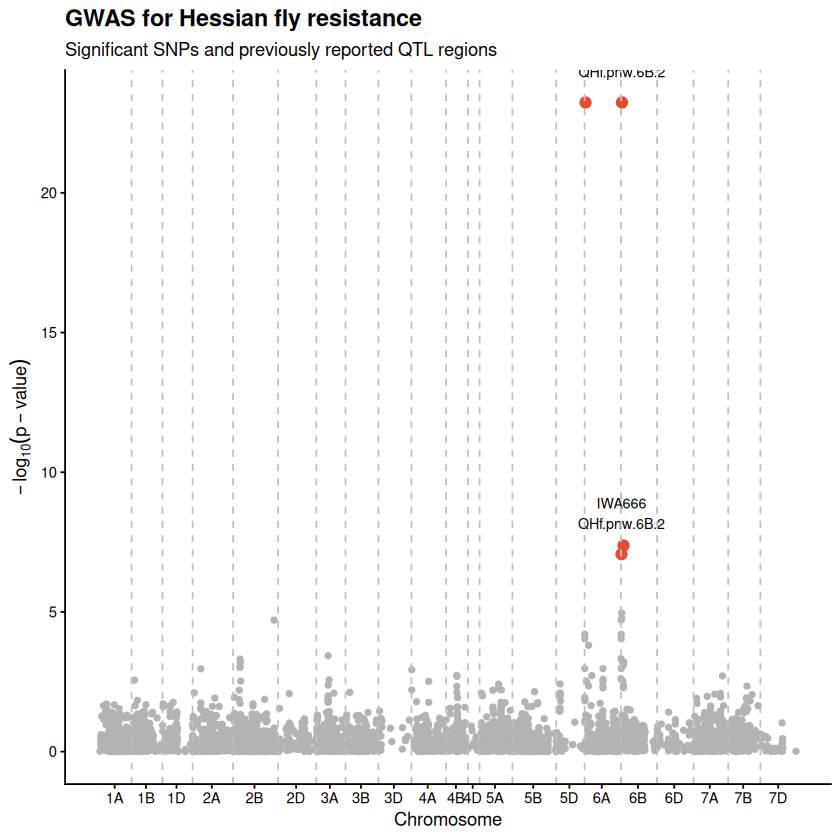

In [64]:
p_hessian <- ggplot(gwas_hf, aes(x = pos_plot, y = -log10(pValue))) +

  # Todos los SNP
  geom_point(color = "grey70", size = 1.4) +

  # SNP significativos
  geom_point(
    data = sig_hf,
    color = "#E64B35",
    size = 2.8
  ) +

  # Etiquetas de SNP y QTL
  geom_text(
    data = labels_hf,
    aes(
      x = pos_plot,
      y = -log10(pValue),
      label = paste0(snp, "\n", QTL)
    ),
    vjust = -0.8,
    size = 3,
    check_overlap = TRUE
  ) +

  # Separación entre cromosomas
  geom_vline(
    xintercept = chr_limits$offset[-1],
    linetype = "dashed",
    color = "grey75"
  ) +

  scale_x_continuous(
    breaks = chr_limits$offset + chr_limits$pos / 2,
    labels = as.character(chr_limits$chr)
  ) +

  labs(
    title = "GWAS for Hessian fly resistance",
    subtitle = "Significant SNPs and previously reported QTL regions",
    x = "Chromosome",
    y = expression(-log[10](p-value))
  ) +

  theme_classic() +

  theme(
    plot.title = element_text(face = "bold", size = 14),
    axis.text.x = element_text(angle = 0, hjust = 0.5)
  )

print(p_hessian)

In [67]:
ggsave(
  "Manhattan_Hessian_fly_QTL.png",
  plot = p_hessian,
  width = 15,
  height = 9,
  dpi = 300
)

ggsave(
  "Manhattan_Hessian_fly_QTL.pdf",
  plot = p_hessian,
  width = 15,
  height = 9
)

In [68]:
# Cantidad de SNP significativos por fenotipo
sig_por_rasgo <- as.data.frame(
  sort(table(sig_snps$trait), decreasing = TRUE)
)

names(sig_por_rasgo) <- c("Fenotipo", "SNP_significativos")

sig_por_rasgo

# SNP significativos de los tres fenotipos identificados
for (rasgo in c(
  "Stripe rust",
  "Septoria tritici blotch"
)) {

  cat("\n========================\n")
  cat("FENOTIPO:", rasgo, "\n")
  cat("========================\n")

  print(
    subset(
      sig_snps,
      trait == rasgo,
      select = c(trait, snp, chr, pos, pValue, LOD)
    )
  )
}

Fenotipo,SNP_significativos
<fct>,<int>
...4,11
...3,7
...11,6
...10,5
Hessian fly,4
...8,3
...9,3
...12,2
...17,2



FENOTIPO: Stripe rust 
[1] trait  snp    chr    pos    pValue LOD   
<0 rows> (o 0- extensión row.names)

FENOTIPO: Septoria tritici blotch 
[1] trait  snp    chr    pos    pValue LOD   
<0 rows> (o 0- extensión row.names)


In [69]:
# Stripe rust
stripe_all <- subset(gwas_all, trait == "Stripe rust")

# Septoria tritici blotch
septoria_all <- subset(gwas_all, trait == "Septoria tritici blotch")

# Mostrar los SNP con los valores de p más pequeños
head(stripe_all[order(stripe_all$pValue),
                c("trait", "snp", "chr", "pos", "pValue", "LOD")], 10)

head(septoria_all[order(septoria_all$pValue),
                  c("trait", "snp", "chr", "pos", "pValue", "LOD")], 10)

,trait,snp,chr,pos,pValue,LOD
,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>
1805,Stripe rust,IWA3176,2B,202,1.022984e-05,4.990131
1804,Stripe rust,IWA2873,2B,202,1.616539e-05,4.791414
1793,Stripe rust,IWA2702,2B,196,2.807418e-05,4.551693
1791,Stripe rust,IWA2379,2B,196,6.499970e-05,4.187089
1792,Stripe rust,IWA2701,2B,196,8.650197e-05,4.062974
4003,Stripe rust,IWA6902,5B,205,1.040855e-04,3.982610
1797,Stripe rust,IWA2676,2B,200,2.198885e-04,3.657798
532,Stripe rust,IWA63,1B,18,3.269784e-04,3.485481
1795,Stripe rust,IWA2678,2B,197,4.920453e-04,3.307995


,trait,snp,chr,pos,pValue,LOD
,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>
105014,Septoria tritici blotch,IWA6263,2B,2,0.0001222110,3.912890
108476,Septoria tritici blotch,IWA349,6B,126,0.0008523855,3.069364
109106,Septoria tritici blotch,IWA6608,7B,103,0.0010278707,2.988062
107161,Septoria tritici blotch,IWA1,5A,123,0.0018140913,2.741341
107166,Septoria tritici blotch,IWA589,5A,123,0.0018140913,2.741341
109105,Septoria tritici blotch,IWA3928,7B,103,0.0022450580,2.648772
109104,Septoria tritici blotch,IWA3927,7B,103,0.0027727541,2.557089
105027,Septoria tritici blotch,IWA3005,2B,9,0.0033336096,2.477085
107960,Septoria tritici blotch,IWA215,6A,90,0.0036299930,2.440094


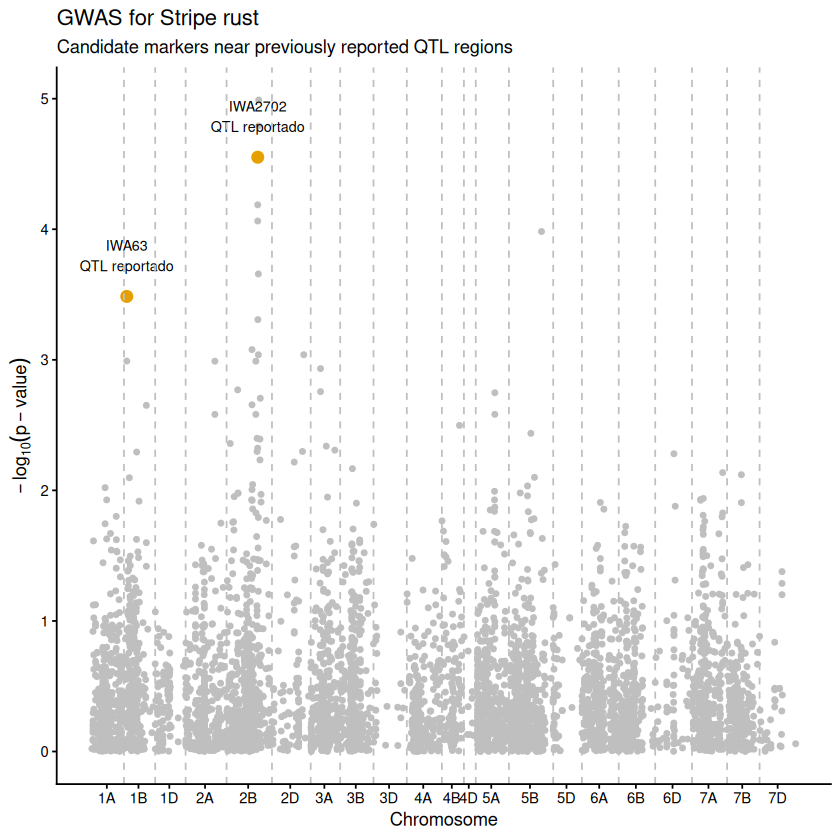

In [70]:
library(ggplot2)

# Datos del fenotipo
gwas_stripe <- subset(gwas_all, trait == "Stripe rust")

gwas_stripe <- gwas_stripe[
  !is.na(gwas_stripe$pos) &
  !is.na(gwas_stripe$pValue) &
  gwas_stripe$pValue > 0, ]

# Marcadores candidatos para anotación
stripe_qtl <- data.frame(
  snp = c("IWA63", "IWA2702"),
  chr = c("1B", "2B"),
  pos = c(18, 196),
  annotation = c(
    "IWA63\nQTL reportado",
    "IWA2702\nQTL reportado"
  )
)

# Orden cromosómico
chr_order <- paste0(rep(1:7, each = 3), rep(c("A", "B", "D"), 7))

gwas_stripe$chr <- factor(gwas_stripe$chr, levels = chr_order)
stripe_qtl$chr <- factor(stripe_qtl$chr, levels = chr_order)

# Calcular posiciones acumuladas
chr_limits <- aggregate(pos ~ chr, data = gwas_stripe, FUN = max)
chr_limits <- chr_limits[order(match(as.character(chr_limits$chr),
                                     chr_order)), ]

gap <- max(chr_limits$pos) * 0.05

chr_limits$offset <- c(
  0,
  head(cumsum(chr_limits$pos + gap), -1)
)

gwas_stripe <- merge(
  gwas_stripe,
  chr_limits[, c("chr", "offset")],
  by = "chr"
)

stripe_qtl <- merge(
  stripe_qtl,
  chr_limits[, c("chr", "offset")],
  by = "chr"
)

gwas_stripe$pos_plot <- gwas_stripe$pos + gwas_stripe$offset
stripe_qtl$pos_plot <- stripe_qtl$pos + stripe_qtl$offset

# Manhattan plot
p_stripe <- ggplot(gwas_stripe,
                   aes(x = pos_plot, y = -log10(pValue))) +

  geom_point(color = "grey75", size = 1.3) +

  # Destacar marcadores candidatos
  geom_point(
    data = stripe_qtl,
    aes(x = pos_plot, y = -log10(
      gwas_stripe$pValue[match(snp, gwas_stripe$snp)]
    )),
    color = "#E69F00",
    size = 3
  ) +

  geom_text(
    data = stripe_qtl,
    aes(
      x = pos_plot,
      y = -log10(gwas_stripe$pValue[
        match(snp, gwas_stripe$snp)
      ]),
      label = annotation
    ),
    vjust = -0.8,
    size = 3
  ) +

  geom_vline(
    xintercept = chr_limits$offset[-1],
    linetype = "dashed",
    color = "grey75"
  ) +

  scale_x_continuous(
    breaks = chr_limits$offset + chr_limits$pos / 2,
    labels = as.character(chr_limits$chr)
  ) +

  labs(
    title = "GWAS for Stripe rust",
    subtitle = "Candidate markers near previously reported QTL regions",
    x = "Chromosome",
    y = expression(-log[10](p-value))
  ) +

  theme_classic()

print(p_stripe)

ggsave("Manhattan_Stripe_rust_QTL.png",
       plot = p_stripe, width = 13, height = 6, dpi = 300)

ggsave("Manhattan_Stripe_rust_QTL.pdf",
       plot = p_stripe, width = 13, height = 6)

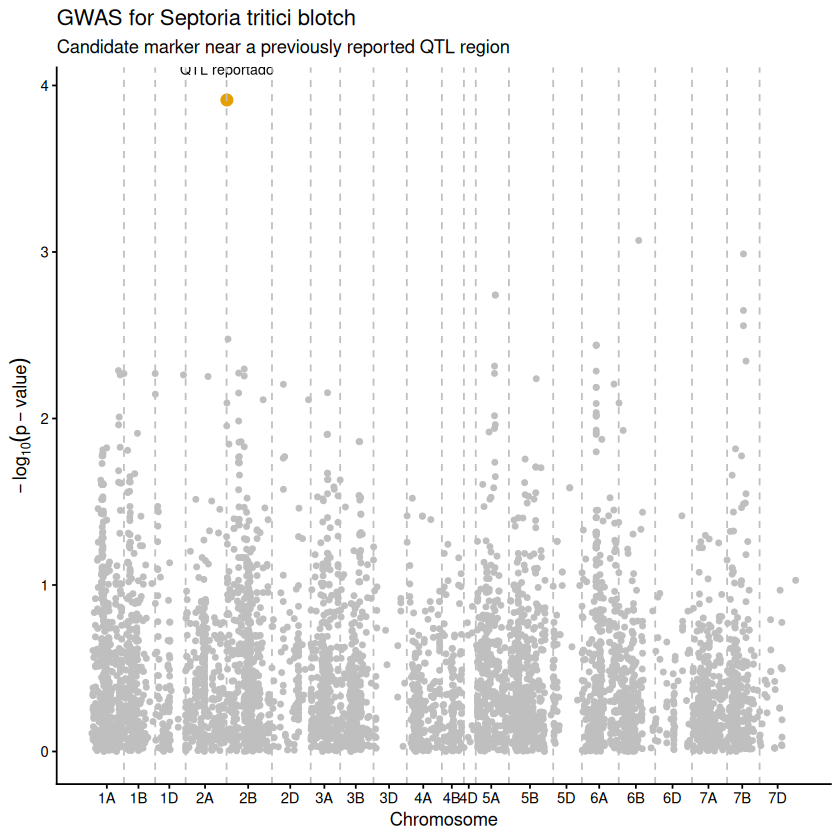

In [71]:
# Datos del fenotipo
gwas_septoria <- subset(
  gwas_all,
  trait == "Septoria tritici blotch"
)

gwas_septoria <- gwas_septoria[
  !is.na(gwas_septoria$pos) &
  !is.na(gwas_septoria$pValue) &
  gwas_septoria$pValue > 0, ]

# Marcador candidato para anotación
septoria_qtl <- data.frame(
  snp = "IWA6263",
  chr = "2B",
  pos = 2,
  annotation = "IWA6263\nQTL reportado"
)

# Orden cromosómico
gwas_septoria$chr <- factor(
  gwas_septoria$chr,
  levels = chr_order
)

septoria_qtl$chr <- factor(
  septoria_qtl$chr,
  levels = chr_order
)

# Calcular posiciones acumuladas
chr_limits <- aggregate(pos ~ chr, data = gwas_septoria, FUN = max)

chr_limits <- chr_limits[
  order(match(as.character(chr_limits$chr), chr_order)), ]

gap <- max(chr_limits$pos) * 0.05

chr_limits$offset <- c(
  0,
  head(cumsum(chr_limits$pos + gap), -1)
)

gwas_septoria <- merge(
  gwas_septoria,
  chr_limits[, c("chr", "offset")],
  by = "chr"
)

septoria_qtl <- merge(
  septoria_qtl,
  chr_limits[, c("chr", "offset")],
  by = "chr"
)

gwas_septoria$pos_plot <- gwas_septoria$pos +
  gwas_septoria$offset

septoria_qtl$pos_plot <- septoria_qtl$pos +
  septoria_qtl$offset

# Obtener el valor p del marcador
septoria_qtl$pValue <- gwas_septoria$pValue[
  match(septoria_qtl$snp, gwas_septoria$snp)
]

septoria_qtl$logP <- -log10(septoria_qtl$pValue)

# Manhattan plot
p_septoria <- ggplot(
  gwas_septoria,
  aes(x = pos_plot, y = -log10(pValue))
) +

  geom_point(color = "grey75", size = 1.3) +

  # Destacar marcador candidato
  geom_point(
    data = septoria_qtl,
    aes(x = pos_plot, y = logP),
    color = "#E69F00",
    size = 3
  ) +

  geom_text(
    data = septoria_qtl,
    aes(x = pos_plot, y = logP, label = annotation),
    vjust = -0.8,
    size = 3
  ) +

  geom_vline(
    xintercept = chr_limits$offset[-1],
    linetype = "dashed",
    color = "grey75"
  ) +

  scale_x_continuous(
    breaks = chr_limits$offset + chr_limits$pos / 2,
    labels = as.character(chr_limits$chr)
  ) +

  labs(
    title = "GWAS for Septoria tritici blotch",
    subtitle = "Candidate marker near a previously reported QTL region",
    x = "Chromosome",
    y = expression(-log[10](p-value))
  ) +

  theme_classic()

print(p_septoria)

ggsave("Manhattan_Septoria_tritici_blotch_QTL.png",
       plot = p_septoria, width = 13, height = 6, dpi = 300)

ggsave("Manhattan_Septoria_tritici_blotch_QTL.pdf",
       plot = p_septoria, width = 13, height = 6)